Prepared fold 1: 7000 augmented train, 400 original validation
Prepared fold 2: 8400 augmented train, 200 original validation
Prepared fold 3: 8400 augmented train, 200 original validation
Prepared fold 4: 7000 augmented train, 400 original validation
Prepared fold 5: 8400 augmented train, 200 original validation
DATA SUMMARY
Original frames: 1400
Input shape: (1400, 24, 32, 1)
Background frames: 118


Class,Clean Air,HFC
Session,,
1,100,100
2,100,100
3,100,100
4,100,100
5,100,100
6,100,100
7,100,100


,Original validation frames
validation_fold,
1,400
2,200
3,200
4,400
5,200


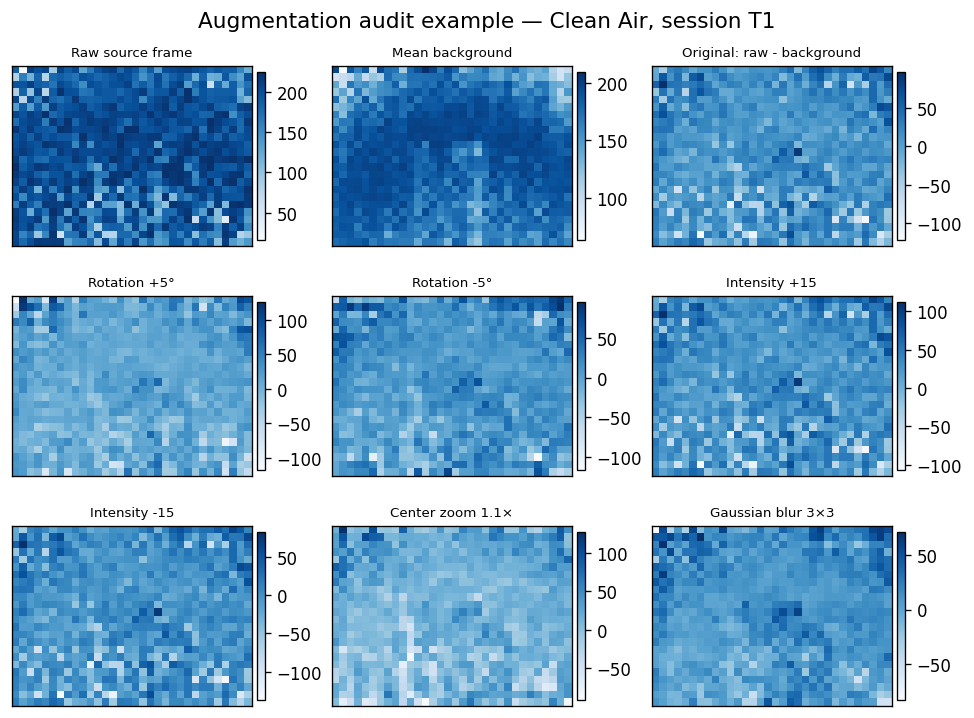

Source: C:\1. Tukadi_ITS\X_learning5\Clean Air\Non HFC (1).csv


In [1]:
"""Unified reviewer-validation pipeline for the IJIES manuscript.

One preprocessing definition is shared by grouped CNN validation, Table 3
ablation/spatial controls, Table 13 classifier baselines, final retraining,
and the machine-readable reproducibility artifact.
"""

from __future__ import annotations

from dataclasses import asdict, dataclass
from hashlib import sha256
from itertools import combinations
from pathlib import Path
import json, os, random, re, time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam


@dataclass(frozen=True)
class Config:
    original_root: str = r"C:\1. Tukadi_ITS\X_learning5"
    holdout_root: str = r"C:\1. Tukadi_ITS\X_testing5"
    output_dir: str = r"C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_master_outputs"
    seed: int = 42
    n_splits: int = 5
    max_epochs: int = 50
    patience: int = 30
    batch_size: int = 32
    learning_rate: float = 0.001
    images_per_class_session: int = 100
    expected_original: int = 1400
    run_pair_ablations: bool = False


REGIONS = {
    "4.63 um": (2, 11, 2, 14), "5.64 um": (2, 11, 18, 30),
    "9.50 um": (13, 22, 2, 14), "10.20 um": (13, 22, 18, 30),
}
PERMUTATIONS = {
    "Horizontal swap": {"4.63 um":"5.64 um","5.64 um":"4.63 um","9.50 um":"10.20 um","10.20 um":"9.50 um"},
    "Vertical swap": {"4.63 um":"9.50 um","9.50 um":"4.63 um","5.64 um":"10.20 um","10.20 um":"5.64 um"},
    "Diagonal swap": {"4.63 um":"10.20 um","10.20 um":"4.63 um","5.64 um":"9.50 um","9.50 um":"5.64 um"},
    "Cyclic permutation": {"4.63 um":"10.20 um","5.64 um":"4.63 um","9.50 um":"5.64 um","10.20 um":"9.50 um"},
}
SHIFTS = {"Row -1":(-1,0),"Row +1":(1,0),"Column -1":(0,-1),"Column +1":(0,1),
          "Row -2":(-2,0),"Row +2":(2,0),"Column -2":(0,-2),"Column +2":(0,2)}
LABEL_TO_ID = {"Clean Air": 0, "HFC": 1}


def seed_all(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)


def read_frame(path):
    try: a = pd.read_csv(path, header=None).to_numpy(dtype=np.float32)
    except Exception: return None
    if a.shape == (24, 32): return a
    return a.reshape(24, 32) if a.size == 768 else None


def number(path):
    m = re.search(r"\((\d+)\)", Path(path).stem)
    if not m: raise ValueError(f"Missing sequence number: {path}")
    return int(m.group(1))


def file_hash(path):
    h = sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""): h.update(block)
    return h.hexdigest()


def load_master(config=Config()):
    root, out = Path(config.original_root), Path(config.output_dir)
    out.mkdir(parents=True, exist_ok=True); seed_all(config.seed)
    bg_paths, bg_frames = [], []
    for p in sorted((root / "Background").glob("*.csv")):
        a = read_frame(p)
        if a is not None: bg_paths.append(str(p)); bg_frames.append(a)
    if not bg_frames: raise RuntimeError("No valid background frames")
    background = np.mean(np.stack(bg_frames), axis=0).astype(np.float32)
    raw, labels, groups, paths = [], [], [], []
    for name, label in LABEL_TO_ID.items():
        for p in sorted((root / name).glob("*.csv")):
            a = read_frame(p)
            if a is None: continue
            raw.append(a); labels.append(label)
            groups.append((number(p) - 1) // config.images_per_class_session)
            paths.append(str(p))
    raw = np.asarray(raw, np.float32); y = np.asarray(labels, int)
    groups, paths = np.asarray(groups, int), np.asarray(paths)
    if len(raw) != config.expected_original: raise ValueError(f"Expected {config.expected_original}, found {len(raw)}")
    delta = (raw - background)[..., None]
    splits = list(StratifiedGroupKFold(config.n_splits, shuffle=True, random_state=config.seed).split(delta, y, groups))
    fold_of = np.full(len(y), -1, int)
    for fold, (tr, va) in enumerate(splits, 1):
        assert not (set(groups[tr]) & set(groups[va])); fold_of[va] = fold
    manifest = pd.DataFrame({"source_index":np.arange(len(y)),"path":paths,"label":y,"session":groups,"validation_fold":fold_of})
    manifest.to_csv(out / "source_fold_manifest.csv", index=False)
    pd.DataFrame({"path":bg_paths,"sha256":[file_hash(p) for p in bg_paths]}).to_csv(out / "background_manifest.csv", index=False)
    return {"config":config,"out":out,"raw":raw,"delta":delta,"y":y,"groups":groups,"paths":paths,
            "background":background,"background_paths":bg_paths,"splits":splits,"manifest":manifest}


def variants(raw):
    raw = np.clip(raw, 0, 255).astype(np.uint8); h, w = raw.shape
    center = (w // 2, h // 2)
    def rot(angle):
        m = cv2.getRotationMatrix2D(center, angle, 1.0)
        return cv2.warpAffine(raw, m, (w, h), borderMode=cv2.BORDER_REFLECT)
    nw, nh = int(w / 1.1), int(h / 1.1); x0, y0 = w//2-nw//2, h//2-nh//2
    zoom = cv2.resize(raw[y0:y0+nh, x0:x0+nw], (w,h), interpolation=cv2.INTER_LINEAR)
    return [raw, rot(5), rot(-5), np.clip(raw.astype(np.int16)+15,0,255).astype(np.uint8),
            np.clip(raw.astype(np.int16)-15,0,255).astype(np.uint8), zoom, cv2.GaussianBlur(raw,(3,3),0)]


def augment(raw, y, background):
    xx, yy = [], []
    for frame, label in zip(raw, y):
        for v in variants(frame): xx.append((v.astype(np.float32)-background)[...,None]); yy.append(label)
    return np.asarray(xx,np.float32), np.asarray(yy,int)


def prepared_folds(master):
    cache = []
    for fold, (tr, va) in enumerate(master["splits"], 1):
        xtr, ytr = augment(master["raw"][tr], master["y"][tr], master["background"])
        cache.append({"fold":fold,"tr":tr,"va":va,"xtr":xtr,"ytr":ytr,
                      "xva":master["delta"][va],"yva":master["y"][va]})
        print(f"Prepared fold {fold}: {len(xtr)} augmented train, {len(va)} original validation")
    return cache


def show_data_and_augmentation(master, sample_index=0):
    """Display data counts and one auditable augmentation example."""
    if not 0 <= sample_index < len(master["raw"]):
        raise IndexError(f"sample_index must be between 0 and {len(master['raw'])-1}")
    label_names = {value: key for key, value in LABEL_TO_ID.items()}
    counts = pd.crosstab(
        pd.Series(master["groups"] + 1, name="Session"),
        pd.Series([label_names[int(v)] for v in master["y"]], name="Class"),
    )
    fold_counts = master["manifest"].groupby("validation_fold").size().rename("Original validation frames")
    print("DATA SUMMARY")
    print("Original frames:", len(master["raw"]))
    print("Input shape:", master["delta"].shape)
    print("Background frames:", len(master["background_paths"]))
    display(counts)
    display(fold_counts.to_frame())

    raw = master["raw"][sample_index]
    background = master["background"]
    processed = [(v.astype(np.float32) - background) for v in variants(raw)]
    images = [raw, background, *processed]
    titles = [
        "Raw source frame", "Mean background", "Original: raw - background",
        "Rotation +5°", "Rotation -5°", "Intensity +15",
        "Intensity -15", "Center zoom 1.1×", "Gaussian blur 3×3",
    ]
    fig, axes = plt.subplots(3, 3, figsize=(8, 6), dpi=120, constrained_layout=True)
    for ax, image, title in zip(axes.ravel(), images, titles):
        artist = ax.imshow(image, cmap="Blues")
        ax.set_title(title, fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(artist, ax=ax, fraction=0.040, pad=0.02, shrink=0.80)
    label = label_names[int(master["y"][sample_index])]
    session = int(master["groups"][sample_index]) + 1
    fig.suptitle(f"Augmentation audit example — {label}, session T{session}", fontsize=13)
    plt.show()
    print("Source:", master["paths"][sample_index])


def cnn_model(config):
    m = Sequential([Input((24,32,1)),Conv2D(32,3,activation="relu",padding="same"),BatchNormalization(),MaxPooling2D(2),
        Conv2D(64,3,activation="relu",padding="same"),BatchNormalization(),MaxPooling2D(2),
        Conv2D(128,3,activation="relu",padding="same"),BatchNormalization(),MaxPooling2D(2),
        Flatten(),Dense(128,activation="relu"),Dropout(.5),Dense(2,activation="softmax")])
    m.compile(Adam(config.learning_rate),"categorical_crossentropy",metrics=["accuracy"]); return m


def metric_row(y, pred):
    p,r,f,_ = precision_recall_fscore_support(y,pred,average="macro",zero_division=0)
    return accuracy_score(y,pred),p,r,f


def run_cnn(master, cache):
    c, out = master["config"], master["out"]; fold_rows, pred_rows, best_epochs = [], [], []
    for pack in cache:
        fold=pack["fold"]; tf.keras.backend.clear_session(); seed_all(c.seed+fold); m=cnn_model(c)
        cb=EarlyStopping(monitor="val_loss",mode="min",patience=c.patience,restore_best_weights=True)
        hist=m.fit(pack["xtr"],tf.keras.utils.to_categorical(pack["ytr"],2),validation_data=(pack["xva"],tf.keras.utils.to_categorical(pack["yva"],2)),
                   epochs=c.max_epochs,batch_size=c.batch_size,callbacks=[cb],verbose=0)
        prob=m.predict(pack["xva"],verbose=0); pred=prob.argmax(1); acc,p,r,f=metric_row(pack["yva"],pred)
        be=int(np.argmin(hist.history["val_loss"])+1); best_epochs.append(be)
        fold_rows.append({"fold":fold,"n_validation":len(pred),"accuracy":acc,"macro_precision":p,"macro_recall":r,"macro_f1":f,"best_epoch":be})
        for j,src in enumerate(pack["va"]): pred_rows.append({"fold":fold,"source_index":int(src),"path":master["paths"][src],"session":int(master["groups"][src]),"true":int(pack["yva"][j]),"pred":int(pred[j]),"p_hfc":float(prob[j,1])})
        print(f"CNN fold {fold}: accuracy={acc:.4f}, best epoch={be}")
    folds, preds = pd.DataFrame(fold_rows), pd.DataFrame(pred_rows)
    folds.to_csv(out/"cnn_fold_metrics.csv",index=False); preds.to_csv(out/"cnn_source_predictions.csv",index=False)
    acc,p,r,f=metric_row(preds.true,preds.pred)
    summary={"pooled_accuracy":acc,"pooled_macro_precision":p,"pooled_macro_recall":r,"pooled_macro_f1":f,
             "fold_accuracy_mean":folds.accuracy.mean(),"fold_accuracy_sample_sd":folds.accuracy.std(ddof=1),"best_epochs":best_epochs,"final_epochs":int(np.median(best_epochs))}
    (out/"cnn_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
    tf.keras.backend.clear_session(); seed_all(c.seed); final=cnn_model(c)
    xall,yall=augment(master["raw"],master["y"],master["background"])
    final.fit(xall,tf.keras.utils.to_categorical(yall,2),epochs=summary["final_epochs"],batch_size=c.batch_size,shuffle=True,verbose=1)
    final.save(out/"final_model_fixed_epoch.keras")
    return {"folds":folds,"predictions":preds,"summary":summary,"model":final}


def mask_regions(x, names):
    z=np.zeros_like(x)
    for n in names:
        r0,r1,c0,c1=REGIONS[n]; z[:,r0:r1,c0:c1,:]=x[:,r0:r1,c0:c1,:]
    return z


def permute(x, mapping):
    z=np.zeros_like(x)
    for target,source in mapping.items():
        tr0,tr1,tc0,tc1=REGIONS[target]; sr0,sr1,sc0,sc1=REGIONS[source]
        z[:,tr0:tr1,tc0:tc1,:]=x[:,sr0:sr1,sc0:sc1,:]
    return z


def shifted(x, dr, dc):
    z=np.zeros_like(x)
    for r0,r1,c0,c1 in REGIONS.values(): z[:,r0:r1,c0:c1,:]=x[:,r0+dr:r1+dr,c0+dc:c1+dc,:]
    return z


def summarize_predictions(preds, baseline=None):
    rows=[]
    for name,g in preds.groupby("condition",sort=False):
        acc,p,r,f=metric_row(g.true,g.pred)
        fa=pd.Series([accuracy_score(q.true,q.pred) for _,q in g.groupby("fold")])
        rows.append({"condition":name,"pooled_accuracy":acc,"pooled_macro_f1":f,"fold_accuracy_mean":fa.mean(),"fold_accuracy_sample_sd":fa.std(ddof=1),"n_original_predictions":len(g)})
    s=pd.DataFrame(rows)
    if baseline:
        b=float(s.loc[s.condition==baseline,"pooled_accuracy"].iloc[0]); s["delta_vs_baseline_pp"]=100*(s.pooled_accuracy-b)
    return s


def run_table3(master, cache, cnn_result):
    c,out=master["config"],master["out"]; names=tuple(REGIONS)
    conditions={"Four-region baseline":names}
    for n in names: conditions[f"Single: {n}"]=(n,)
    for n in names: conditions[f"Leave one out: {n}"]=tuple(x for x in names if x!=n)
    if c.run_pair_ablations:
        for a,b in combinations(names,2): conditions[f"Pair: {a} + {b}"]=(a,b)
    pred_rows=[]
    # Reuse the exact full-frame CNN predictions, preventing Table 3/Table 4 drift.
    for row in cnn_result["predictions"].itertuples(): pred_rows.append({"control":"retrained","condition":"Raw full frame (spatial reference)","fold":row.fold,"source_index":row.source_index,"true":row.true,"pred":row.pred})
    for condition,active in conditions.items():
        for pack in cache:
            fold=pack["fold"]; tf.keras.backend.clear_session(); seed_all(c.seed+fold); m=cnn_model(c)
            xtr,xva=mask_regions(pack["xtr"],active),mask_regions(pack["xva"],active)
            cb=EarlyStopping(monitor="val_loss",mode="min",patience=c.patience,restore_best_weights=True)
            m.fit(xtr,tf.keras.utils.to_categorical(pack["ytr"],2),validation_data=(xva,tf.keras.utils.to_categorical(pack["yva"],2)),epochs=c.max_epochs,batch_size=c.batch_size,callbacks=[cb],verbose=0)
            # Baseline model is also used for frozen permutation/registration controls.
            tests={condition:xva}
            if condition=="Four-region baseline":
                tests.update({k:permute(pack["xva"],v) for k,v in PERMUTATIONS.items()})
                tests.update({f"Shift {k}":shifted(pack["xva"],*v) for k,v in SHIFTS.items()})
            for test_name,xt in tests.items():
                pr=m.predict(xt,verbose=0).argmax(1); control="retrained" if test_name==condition else "frozen model"
                for j,src in enumerate(pack["va"]): pred_rows.append({"control":control,"condition":test_name,"fold":fold,"source_index":int(src),"true":int(pack["yva"][j]),"pred":int(pr[j])})
            print(f"Table 3 {condition}, fold {fold} complete")
    preds=pd.DataFrame(pred_rows); preds.to_csv(out/"table3_source_predictions.csv",index=False)
    rt=summarize_predictions(preds[preds.control=="retrained"],"Four-region baseline")
    fr=summarize_predictions(preds[preds.control=="frozen model"])
    baseline=float(rt.loc[rt.condition=="Four-region baseline","pooled_accuracy"].iloc[0])
    fr["delta_vs_baseline_pp"]=100*(fr.pooled_accuracy-baseline)
    summary=pd.concat([rt.assign(control="retrained"),fr.assign(control="frozen model")],ignore_index=True)
    summary.to_csv(out/"table3_summary.csv",index=False); return {"predictions":preds,"summary":summary}


def run_table13(master, cache, cnn_result):
    out=master["out"]
    models={"Random forest":RandomForestClassifier(n_estimators=300,max_features="sqrt",class_weight="balanced",random_state=42,n_jobs=-1),
            "RBF SVM":Pipeline([("scale",StandardScaler()),("model",SVC(C=1,kernel="rbf",gamma="scale"))]),
            "K-nearest neighbors":Pipeline([("scale",StandardScaler()),("model",KNeighborsClassifier(n_neighbors=5))]),
            "Linear SVM":Pipeline([("scale",StandardScaler()),("model",SVC(C=1,kernel="linear"))])}
    rows=[]
    for name,base in models.items():
        for pack in cache:
            model=clone(base); model.fit(pack["xtr"].reshape(len(pack["xtr"]),-1),pack["ytr"])
            pred=model.predict(pack["xva"].reshape(len(pack["xva"]),-1))
            for j,src in enumerate(pack["va"]): rows.append({"classifier":name,"fold":pack["fold"],"source_index":int(src),"path":master["paths"][src],"session":int(master["groups"][src]),"true":int(pack["yva"][j]),"pred":int(pred[j])})
            print(f"Table 13 {name}, fold {pack['fold']} complete")
    p=pd.DataFrame(rows); p.to_csv(out/"table13_source_predictions.csv",index=False)
    summary=[]
    for name,g in p.groupby("classifier",sort=False):
        acc,pr,re,f=metric_row(g.true,g.pred)
        fa=pd.Series([accuracy_score(q.true,q.pred) for _,q in g.groupby("fold")])
        summary.append({"classifier":name,"pooled_accuracy":acc,"pooled_macro_f1":f,"fold_accuracy_mean":fa.mean(),"fold_accuracy_sample_sd":fa.std(ddof=1)})
    cs=cnn_result["summary"]; summary.append({"classifier":"Proposed compact CNN","pooled_accuracy":cs["pooled_accuracy"],"pooled_macro_f1":cs["pooled_macro_f1"],"fold_accuracy_mean":cs["fold_accuracy_mean"],"fold_accuracy_sample_sd":cs["fold_accuracy_sample_sd"]})
    s=pd.DataFrame(summary).sort_values("pooled_accuracy",ascending=False); s.to_csv(out/"table13_summary.csv",index=False); return {"predictions":p,"summary":s}


def evaluate_holdout(master, cnn_result):
    root,out=Path(master["config"].holdout_root),master["out"]
    if not root.exists(): print("Holdout folder absent; skipped"); return None
    raw,y,paths=[],[],[]
    for name,label in LABEL_TO_ID.items():
        for p in sorted((root/name).glob("*.csv")):
            a=read_frame(p)
            if a is not None: raw.append(a); y.append(label); paths.append(str(p))
    x=(np.asarray(raw,np.float32)-master["background"])[...,None]; y=np.asarray(y,int)
    prob=cnn_result["model"].predict(x,verbose=0); pred=prob.argmax(1)
    df=pd.DataFrame({"path":paths,"true":y,"pred":pred,"p_hfc":prob[:,1],"correct":pred==y})
    df.to_csv(out/"holdout_source_predictions.csv",index=False); acc,p,r,f=metric_row(y,pred)
    summary={"n":len(y),"accuracy":acc,"macro_precision":p,"macro_recall":r,"macro_f1":f}
    (out/"holdout_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8"); return summary


def finalize_artifact(master, cnn_result, table3_result, table13_result, holdout_summary=None):
    out,c=master["out"],master["config"]
    meta={"config":asdict(c),"background_rule":"pixelwise mean of all valid leak-free background frames",
          "augmentation_rule":"original,+5deg,-5deg,+15 clipped,-15 clipped,1.1x center zoom,3x3 Gaussian blur; training only",
          "validation_rule":"one prediction per original non-augmented source frame","cnn":cnn_result["summary"],"holdout":holdout_summary}
    (out/"protocol_metadata.json").write_text(json.dumps(meta,indent=2),encoding="utf-8")
    hashes=[]
    for p in sorted(out.iterdir()):
        if p.is_file() and p.name!="artifact_hashes.csv": hashes.append({"file":p.name,"sha256":file_hash(p)})
    pd.DataFrame(hashes).to_csv(out/"artifact_hashes.csv",index=False)
    print("Reproducibility artifact:",out)



# Load 1,400 original frames, define the five session-grouped folds,
# and generate augmentation only from each fold's training sources.
config = Config()
master = load_master(config)
fold_cache = prepared_folds(master)
show_data_and_augmentation(master, sample_index=0)


In [2]:
# 1. Grouped five-fold CNN validation and final retraining
cnn_result = run_cnn(master, fold_cache)
display(pd.DataFrame([cnn_result["summary"]]).round(4))



CNN fold 1: accuracy=0.7775, best epoch=3
CNN fold 2: accuracy=0.8300, best epoch=7
CNN fold 3: accuracy=0.7750, best epoch=2
CNN fold 4: accuracy=0.7950, best epoch=4
CNN fold 5: accuracy=0.8700, best epoch=4
Epoch 1/4
307/307 ━━━━━━━━━━━━━━━━━━━━ 14s 27ms/step - accuracy: 0.5815 - loss: 0.7262
Epoch 2/4
307/307 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7058 - loss: 0.5404
Epoch 3/4
307/307 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8279 - loss: 0.3627
Epoch 4/4
307/307 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8958 - loss: 0.2428


,pooled_accuracy,pooled_macro_precision,pooled_macro_recall,pooled_macro_f1,fold_accuracy_mean,fold_accuracy_sample_sd,best_epochs,final_epochs
0,0.8029,0.8047,0.8029,0.8026,0.8095,0.0403,"[3, 7, 2, 4, 4]",4


In [3]:
# 2. Filter-region ablation and position/registration controls (Table 3)
assert "cnn_result" in globals(), "Run the CNN cell above first."
table3_result = run_table3(master, fold_cache, cnn_result)
display(table3_result["summary"].round(4))


Table 3 Four-region baseline, fold 1 complete
Table 3 Four-region baseline, fold 2 complete
Table 3 Four-region baseline, fold 3 complete
Table 3 Four-region baseline, fold 4 complete
Table 3 Four-region baseline, fold 5 complete
Table 3 Single: 4.63 um, fold 1 complete
Table 3 Single: 4.63 um, fold 2 complete
Table 3 Single: 4.63 um, fold 3 complete
Table 3 Single: 4.63 um, fold 4 complete
Table 3 Single: 4.63 um, fold 5 complete
Table 3 Single: 5.64 um, fold 1 complete
Table 3 Single: 5.64 um, fold 2 complete
Table 3 Single: 5.64 um, fold 3 complete
Table 3 Single: 5.64 um, fold 4 complete
Table 3 Single: 5.64 um, fold 5 complete
Table 3 Single: 9.50 um, fold 1 complete
Table 3 Single: 9.50 um, fold 2 complete
Table 3 Single: 9.50 um, fold 3 complete
Table 3 Single: 9.50 um, fold 4 complete
Table 3 Single: 9.50 um, fold 5 complete
Table 3 Single: 10.20 um, fold 1 complete
Table 3 Single: 10.20 um, fold 2 complete
Table 3 Single: 10.20 um, fold 3 complete
Table 3 Single: 10.20 um, fol

,condition,pooled_accuracy,pooled_macro_f1,fold_accuracy_mean,fold_accuracy_sample_sd,n_original_predictions,delta_vs_baseline_pp,control
0,Raw full frame (spatial reference),0.8029,0.8026,0.8095,0.0403,1400,2.0000,retrained
1,Four-region baseline,0.7829,0.7829,0.7790,0.0688,1400,0.0000,retrained
2,Single: 4.63 um,0.6229,0.6182,0.6355,0.0926,1400,-16.0000,retrained
3,Single: 5.64 um,0.7264,0.7247,0.7240,0.0509,1400,-5.6429,retrained
4,Single: 9.50 um,0.6329,0.6258,0.6395,0.0685,1400,-15.0000,retrained
5,Single: 10.20 um,0.6100,0.6044,0.6245,0.1194,1400,-17.2857,retrained
6,Leave one out: 4.63 um,0.7429,0.7428,0.7465,0.0178,1400,-4.0000,retrained
7,Leave one out: 5.64 um,0.6757,0.6754,0.6705,0.1194,1400,-10.7143,retrained
8,Leave one out: 9.50 um,0.7429,0.7420,0.7380,0.0502,1400,-4.0000,retrained
9,Leave one out: 10.20 um,0.7507,0.7492,0.7505,0.0556,1400,-3.2143,retrained


In [4]:
# 3. Same-data classifier comparison (Table 13)
assert "cnn_result" in globals(), "Run the CNN cell above first."
table13_result = run_table13(master, fold_cache, cnn_result)
display(table13_result["summary"].round(4))


Table 13 Random forest, fold 1 complete
Table 13 Random forest, fold 2 complete
Table 13 Random forest, fold 3 complete
Table 13 Random forest, fold 4 complete
Table 13 Random forest, fold 5 complete
Table 13 RBF SVM, fold 1 complete
Table 13 RBF SVM, fold 2 complete
Table 13 RBF SVM, fold 3 complete
Table 13 RBF SVM, fold 4 complete
Table 13 RBF SVM, fold 5 complete
Table 13 K-nearest neighbors, fold 1 complete
Table 13 K-nearest neighbors, fold 2 complete
Table 13 K-nearest neighbors, fold 3 complete
Table 13 K-nearest neighbors, fold 4 complete
Table 13 K-nearest neighbors, fold 5 complete
Table 13 Linear SVM, fold 1 complete
Table 13 Linear SVM, fold 2 complete
Table 13 Linear SVM, fold 3 complete
Table 13 Linear SVM, fold 4 complete
Table 13 Linear SVM, fold 5 complete


,classifier,pooled_accuracy,pooled_macro_f1,fold_accuracy_mean,fold_accuracy_sample_sd
0,Random forest,0.8829,0.8823,0.8925,0.0361
1,RBF SVM,0.8286,0.8282,0.8335,0.0240
4,Proposed compact CNN,0.8029,0.8026,0.8095,0.0403
3,Linear SVM,0.7479,0.7458,0.7515,0.0156
2,K-nearest neighbors,0.7229,0.7126,0.7195,0.0296


In [5]:
# 4. Independent holdout evaluation and reproducibility artifact
required_results = ["cnn_result", "table3_result", "table13_result"]
missing_results = [name for name in required_results if name not in globals()]
assert not missing_results, f"Run the preceding cells first: {missing_results}"

holdout_summary = evaluate_holdout(master, cnn_result)
finalize_artifact(
    master, cnn_result, table3_result, table13_result, holdout_summary
)
print(holdout_summary)


Reproducibility artifact: C:\Users\tukadi\OneDrive\Documents\ChatGPT\New project\ijies_master_outputs
{'n': 600, 'accuracy': 0.8966666666666666, 'macro_precision': 0.8975324039018306, 'macro_recall': 0.8966666666666667, 'macro_f1': 0.8966103767606808}
